In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from pyod.models.auto_encoder import AutoEncoder


In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
data_scaled = pd.read_csv("scaled_training_dataset.csv")
data_test_scaled = pd.read_csv("scaled_test_dataset.csv")

In [4]:
def plot_elbow_method(data, selected_features, max_clusters=10):
    X = data[selected_features].values
    distortions = []
    for i in range(1, max_clusters + 1):
        kmeans = KMeans(n_clusters=i, random_state=42)
        kmeans.fit(X)
        distortions.append(kmeans.inertia_)
    
    plt.figure(figsize=(8,6))
    plt.plot(range(1, max_clusters + 1), distortions, marker='o')
    plt.title('Elbow Method for Optimal Number of Clusters')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Distortion')
    plt.show()


In [5]:

def cluster_and_plot_with_pca(data_scaled, selected_features_clusters, target='is_fraud', n_clusters=3):
    data_cluster = data_scaled[selected_features_clusters].copy()
    data_cluster[target] = data_scaled[target]
    data_cluster['cc_num'] = data_scaled['cc_num']
    
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    data_cluster['cluster'] = kmeans.fit_predict(data_cluster[selected_features_clusters])
    
    data_cluster.set_index('cc_num', inplace=True)
    
    print(f"Clusters added to DataFrame: {data_cluster['cluster'].unique()}")  
    print(data_cluster.head())
    
    summary_stats = data_cluster.groupby('cluster')[selected_features_clusters].agg(['mean', 'median'])
    print("\nSummary Statistics for Each Cluster:")
    print(summary_stats)
    
    print("\nFeature Distributions per Cluster (Summary):")
    for feature in selected_features_clusters:
        cluster_stats = data_cluster.groupby('cluster')[feature].describe()
        print(f"\nFeature: {feature}")
        print(cluster_stats)
    
    centroids = kmeans.cluster_centers_
    print("\nCluster Centroids:")
    for i, centroid in enumerate(centroids):
        print(f"Centroid {i}:")
        for feature, value in zip(selected_features_clusters, centroid):
            print(f"  {feature}: {value:.4f}")
    
    pca = PCA(n_components=2)
    reduced_features = pca.fit_transform(data_cluster[selected_features_clusters])
    
    print("\nExplained Variance Ratio of Each PCA Component:")
    for i, variance in enumerate(pca.explained_variance_ratio_):
        print(f"Component {i + 1}: {variance:.4f}")
    
    print("\nPCA Components (Feature Importance):")
    for i, component in enumerate(pca.components_):
        feature_importances = zip(selected_features_clusters, component)
        sorted_importances = sorted(feature_importances, key=lambda x: abs(x[1]), reverse=True)
        print(f"\nComponent {i + 1}:")
        for feature, importance in sorted_importances:
            print(f"{feature}: {importance:.4f}")
    
    data_cluster['Component 1'] = reduced_features[:, 0]
    data_cluster['Component 2'] = reduced_features[:, 1]
    
    plt.figure(figsize=(8,6))
    sns.scatterplot(x='Component 1', y='Component 2', hue='cluster', data=data_cluster, palette='viridis', alpha=0.7)
    plt.title(f'KMeans Clustering Visualized with PCA')
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    plt.show()

    plt.figure(figsize=(8,6))
    sns.scatterplot(x='Component 1', y='Component 2', hue=target, data=data_cluster, palette='viridis', alpha=0.7)
    plt.title(f'Fraud Distribution Visualized with PCA')
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    plt.show()
    
    return data_cluster


Clustering the selected features can indeed provide insights into the importance and role of card-related features. Here's how:

Behavioral Segmentation: By clustering features related to card transactions (e.g., amt, amt_rolling_mean_7d, avg_daily_trans, etc.), you can identify distinct behavioral segments. This helps in understanding how different groups of cardholders behave, which can be crucial in detecting anomalies or fraudulent patterns.

Feature Contribution: The clusters formed will highlight how these card-related features contribute to grouping transactions. For instance, if amt_rolling_mean_7d plays a significant role in defining clusters, it suggests that recent spending behavior is a critical factor in differentiating transaction patterns.

Fraud Detection: In fraud detection, understanding the importance of card features within clusters helps in identifying which aspects of cardholder behavior are most indicative of fraud. For example, a cluster with unusually high amt values might be more prone to fraudulent activities.

Feature Interaction: Clustering reveals how these features interact and whether certain combinations of features (e.g., high transaction amounts with low category_diversity) are more common in certain clusters. This interaction is often key in understanding the underlying dynamics of card usage.

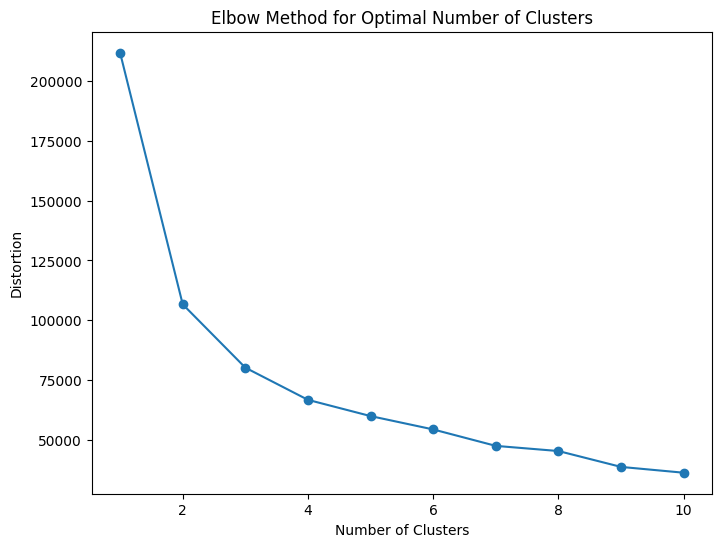

In [11]:
selected_card_features_clusters= ['category_diversity', 'amt_rolling_mean_7d','age_spend_ratio','amt','amt_rolling_mean_15d','avg_daily_trans','num_trans_per_card','distance_between_transactions','amt_std','amt_range']
plot_elbow_method(data_scaled, selected_card_features_clusters)

Clusters added to DataFrame: [0 1 2 4 3]
             category_diversity  amt_rolling_mean_7d  age_spend_ratio  \
cc_num                                                                  
60416207185                 1.0             0.006770         0.001698   
60416207185                 1.0             0.010865         0.002650   
60416207185                 1.0             0.010118         0.001104   
60416207185                 1.0             0.009310         0.000856   
60416207185                 1.0             0.007972         0.000192   

                  amt  amt_rolling_mean_15d  avg_daily_trans  \
cc_num                                                         
60416207185  0.001794              0.014275         0.482007   
60416207185  0.002801              0.022909         0.482007   
60416207185  0.001167              0.021334         0.482007   
60416207185  0.000904              0.019631         0.482007   
60416207185  0.000203              0.016808         0.482007   

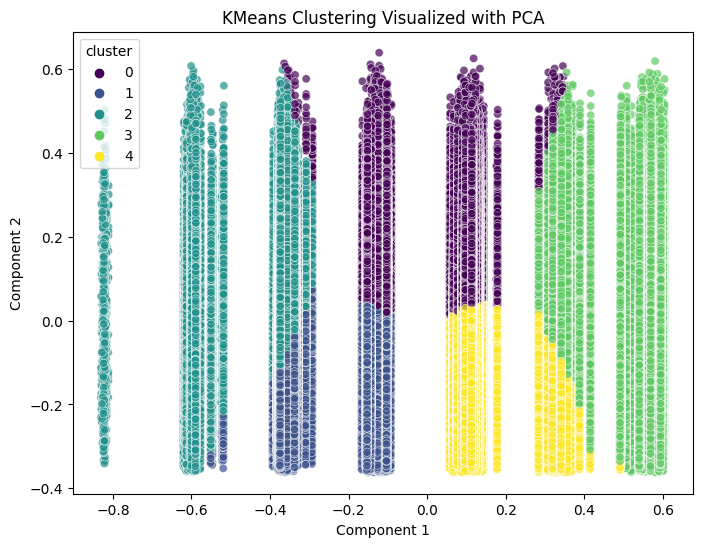

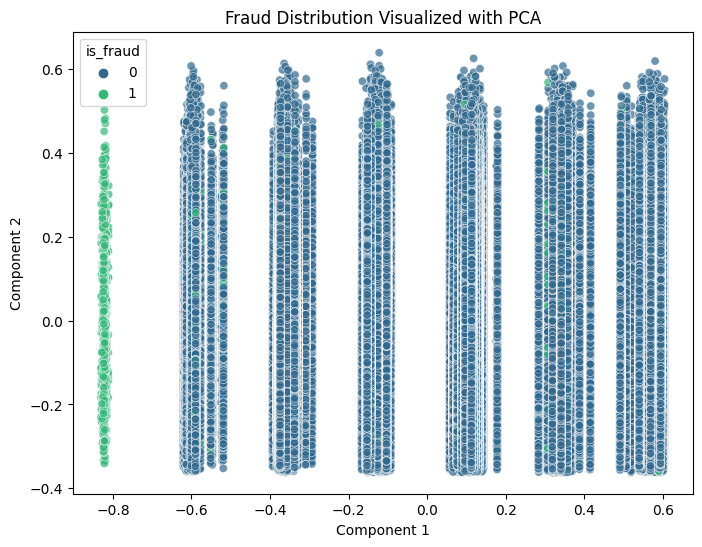

Clusters added to DataFrame: [3 2 1 4 0]
             category_diversity  amt_rolling_mean_7d  age_spend_ratio  \
cc_num                                                                  
60416207185                 1.0             0.030392         0.003405   
60416207185                 1.0             0.026716         0.002822   
60416207185                 1.0             0.026584         0.003810   
60416207185                 1.0             0.030164         0.006458   
60416207185                 1.0             0.025207         0.000080   

                  amt  amt_rolling_mean_15d  avg_daily_trans  \
cc_num                                                         
60416207185  0.003405              0.063817         0.450845   
60416207185  0.002822              0.056099         0.450845   
60416207185  0.003810              0.055822         0.450845   
60416207185  0.006458              0.063338         0.450845   
60416207185  0.000080              0.052930         0.450845   

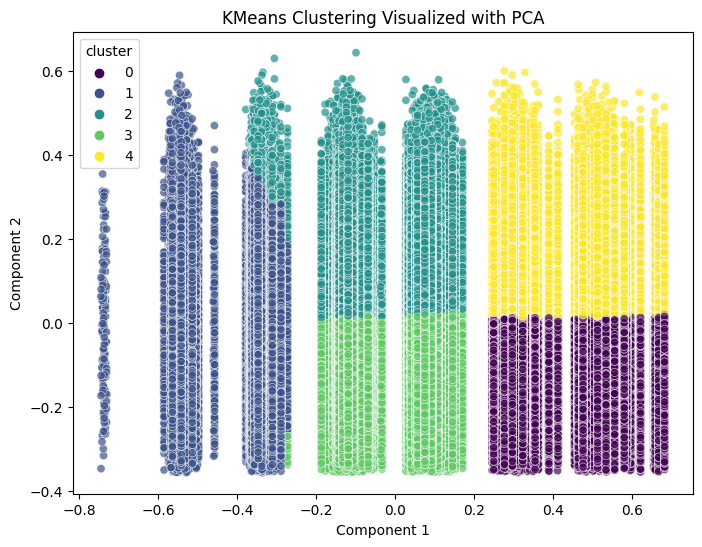

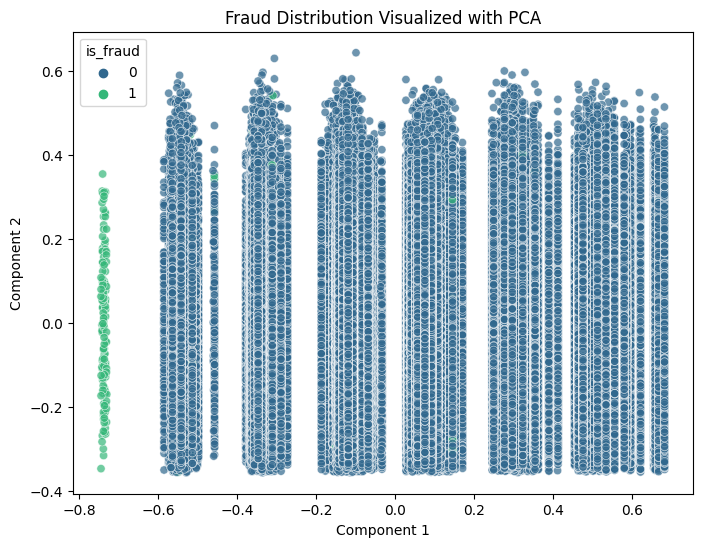

In [12]:
optimal_n_clusters =5
data_cluster_card = cluster_and_plot_with_pca(data_scaled, selected_card_features_clusters, n_clusters=optimal_n_clusters)
data_cluster_card_test = cluster_and_plot_with_pca(data_test_scaled,selected_card_features_clusters,n_clusters=optimal_n_clusters)


** Transaction Volume and Frequency:

- Cluster 0: Characterized by a moderate average transaction amount (mean: 0.002356) and relatively high transaction frequency (avg_daily_trans: 0.567985). This cluster may represent consistent users with moderate spending habits.
- Cluster 3: Shows the highest transaction frequency (avg_daily_trans: 0.909649) and transaction amount variability (amt_std: 0.079690). This could suggest a segment of frequent users, possibly businesses or high-usage individuals.
Low Activity and Potential Risk:

- Cluster 2: Exhibits the lowest transaction frequency (avg_daily_trans: 0.247736) and also has a relatively higher variability in spending patterns (amt_std: 0.068391). This group might represent occasional users or potentially riskier profiles due to irregular behavior.
- Cluster 1: Has moderate spending and transaction frequency but shows higher variability (amt_std: 0.073894), which could be worth monitoring for fraud detection.

** Geospatial Behavior:
- Cluster 0 and Cluster 4: Both have relatively low average distances between transactions, which might indicate users who generally perform transactions within familiar locations.
- Cluster 3: Has a wider range of transaction distances, possibly indicating users who travel or perform transactions over greater distances.

- Cluster 2: Contains the most outliers regarding the age_spend_ratio and the highest variation in transactional behavior. This could point to users who do not follow typical spending patterns and could be flagged for further investigation.


Business Implications:
- Clusters like 2 and 3, with more variability in spending and transaction patterns, could be prioritized for closer monitoring. These clusters might have a higher likelihood of fraudulent activity due to the unusual or inconsistent behavior.

Fraud Distribution Visualized with PCA" shows that fraudulent transactions are distinctly identifiable compared to normal transactions, which helps improve fraud detection 

In [ ]:
fraudulent_summary_by_cluster = data_cluster_card[data_cluster_card['is_fraud'] == 1].groupby('cluster').size()
print(fraudulent_summary_by_cluster)


cluster
0     632
1    1629
2     822
3    1427
4    2921
dtype: int64


fradulent transactions are more present in the cluster 2 ( with low transactions and amount )

## Applying autoencoder with card features

In [9]:
def train_autoencoder_per_cluster(data, feature_columns, cluster_column='cluster', contamination=0.006, lr=0.001):
    """
    Train an autoencoder separately for each cluster in the provided data with a contamination value 0.006 and a learning rate 0.001
    """
    models = {}
    
    for cluster in data[cluster_column].unique():
        cluster_data = data[data[cluster_column] == cluster]
        X_train = cluster_data[feature_columns]
        
        model = AutoEncoder(contamination=contamination, lr=lr)
        model.fit(X_train)
        
        models[cluster] = model
    
    return models


In [14]:
feature_columns = [col for col in data_cluster_card.columns if col not in ['is_fraud', 'cluster', 'Component 1', 'Component 2']]
autoencoder_models = train_autoencoder_per_cluster(data_cluster_card, feature_columns, cluster_column='cluster')


Training: 100%|██████████| 10/10 [11:10<00:00, 67.00s/it]


In [15]:

def evaluate_autoencoder_on_test_per_cluster(autoencoder_models, data_cluster_card_test, feature_columns, cluster_column):
    cluster_results = {}
    
    for cluster in data_cluster_card_test[cluster_column].unique():
        cluster_data = data_cluster_card_test[data_cluster_card_test[cluster_column] == cluster]
        
        X_test = cluster_data[feature_columns].values
        y_test = cluster_data['is_fraud'].values
        
        autoencoder_model = autoencoder_models.get(cluster)
        if autoencoder_model is None:
            print(f"Warning: No model found for cluster {cluster}. Skipping.")
            continue
        
        anomaly_scores = autoencoder_model.decision_function(X_test)
        
        threshold = np.percentile(anomaly_scores, 95)
        
        y_pred = (anomaly_scores > threshold).astype(int)
        
        cm = confusion_matrix(y_test, y_pred)
        
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Fraud', 'Fraud'])
        disp.plot(cmap=plt.cm.Blues)
        plt.title(f'Confusion Matrix for Cluster {cluster}')
        plt.show()
        
        sorted_indices = np.argsort(anomaly_scores)[::-1]
        sorted_scores = anomaly_scores[sorted_indices]
        sorted_labels = y_test[sorted_indices]
        
        actual_fraud_counts = np.sum(y_test)
        detected_fraud_counts = np.sum(sorted_labels[sorted_scores > threshold])
        
        mean_anomaly_score_by_fraud = pd.Series(anomaly_scores, index=y_test).groupby(y_test).mean()

        cluster_results[cluster] = {
            'Actual_Fraud_Counts': actual_fraud_counts,
            'Detected_Fraud_Counts': detected_fraud_counts,
            'Mean_Anomaly_Score_By_Fraud': mean_anomaly_score_by_fraud,
            'Sorted_Scores': sorted_scores[:10],  
            'Sorted_Labels': sorted_labels[:10]  
        }
        
        print(f"\nCluster {cluster} Results:")
        print("Actual fraud counts:")
        print(actual_fraud_counts)
        print("\nDetected fraud counts:")
        print(detected_fraud_counts)
        print("\nMean Anomaly Score by is_fraud:")
        print(mean_anomaly_score_by_fraud)
        
        print("\nTop 10 Anomalies:")
        for idx in range(min(10, len(sorted_scores))):
            print(f"Index: {idx}, Anomaly Score: {sorted_scores[idx]}, Actual Fraud: {sorted_labels[idx]}")
    
    return cluster_results


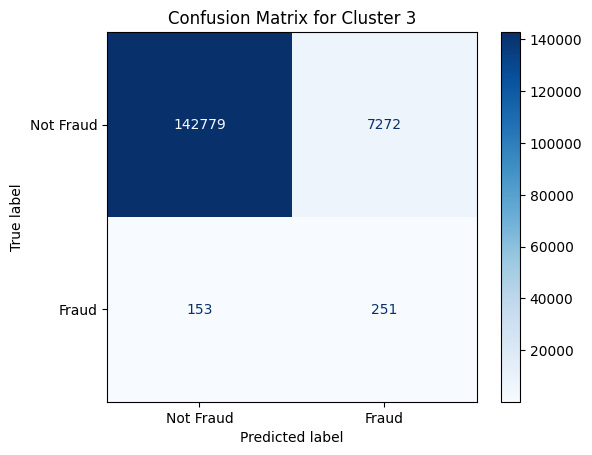


Cluster 3 Results:
Actual fraud counts:
404

Detected fraud counts:
251

Mean Anomaly Score by is_fraud:
0    3.674461
1    5.111934
dtype: float32

Top 10 Anomalies:
Index: 0, Anomaly Score: 25.975299835205078, Actual Fraud: 0
Index: 1, Anomaly Score: 25.777259826660156, Actual Fraud: 0
Index: 2, Anomaly Score: 25.629648208618164, Actual Fraud: 0
Index: 3, Anomaly Score: 25.45848846435547, Actual Fraud: 0
Index: 4, Anomaly Score: 22.252931594848633, Actual Fraud: 0
Index: 5, Anomaly Score: 22.139019012451172, Actual Fraud: 0
Index: 6, Anomaly Score: 18.53202247619629, Actual Fraud: 0
Index: 7, Anomaly Score: 18.398496627807617, Actual Fraud: 0
Index: 8, Anomaly Score: 18.18536949157715, Actual Fraud: 0
Index: 9, Anomaly Score: 18.16189956665039, Actual Fraud: 0


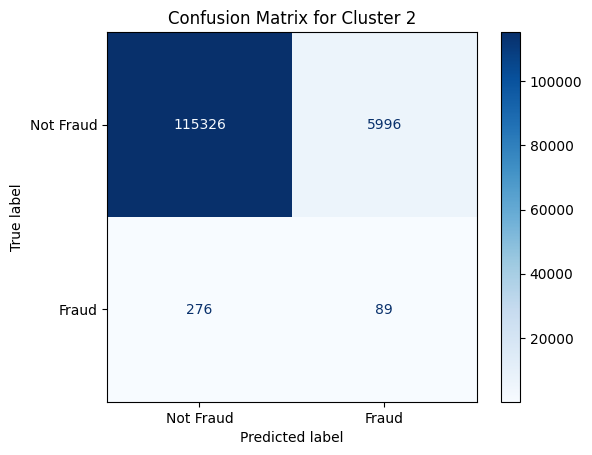


Cluster 2 Results:
Actual fraud counts:
365

Detected fraud counts:
89

Mean Anomaly Score by is_fraud:
0    2.676354
1    3.444746
dtype: float32

Top 10 Anomalies:
Index: 0, Anomaly Score: 22.024015426635742, Actual Fraud: 0
Index: 1, Anomaly Score: 21.387996673583984, Actual Fraud: 0
Index: 2, Anomaly Score: 21.370861053466797, Actual Fraud: 0
Index: 3, Anomaly Score: 21.243486404418945, Actual Fraud: 0
Index: 4, Anomaly Score: 18.026655197143555, Actual Fraud: 0
Index: 5, Anomaly Score: 15.802807807922363, Actual Fraud: 0
Index: 6, Anomaly Score: 15.773232460021973, Actual Fraud: 0
Index: 7, Anomaly Score: 14.962835311889648, Actual Fraud: 0
Index: 8, Anomaly Score: 13.246072769165039, Actual Fraud: 0
Index: 9, Anomaly Score: 13.200396537780762, Actual Fraud: 0


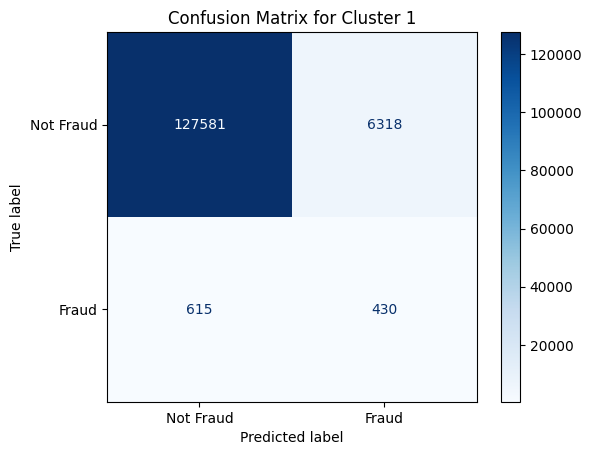


Cluster 1 Results:
Actual fraud counts:
1045

Detected fraud counts:
430

Mean Anomaly Score by is_fraud:
0    2.224116e+00
1    1.107922e+07
dtype: float32

Top 10 Anomalies:
Index: 0, Anomaly Score: 100000000.0, Actual Fraud: 1
Index: 1, Anomaly Score: 100000000.0, Actual Fraud: 1
Index: 2, Anomaly Score: 100000000.0, Actual Fraud: 1
Index: 3, Anomaly Score: 100000000.0, Actual Fraud: 1
Index: 4, Anomaly Score: 100000000.0, Actual Fraud: 1
Index: 5, Anomaly Score: 100000000.0, Actual Fraud: 1
Index: 6, Anomaly Score: 100000000.0, Actual Fraud: 1
Index: 7, Anomaly Score: 100000000.0, Actual Fraud: 1
Index: 8, Anomaly Score: 100000000.0, Actual Fraud: 1
Index: 9, Anomaly Score: 100000000.0, Actual Fraud: 1


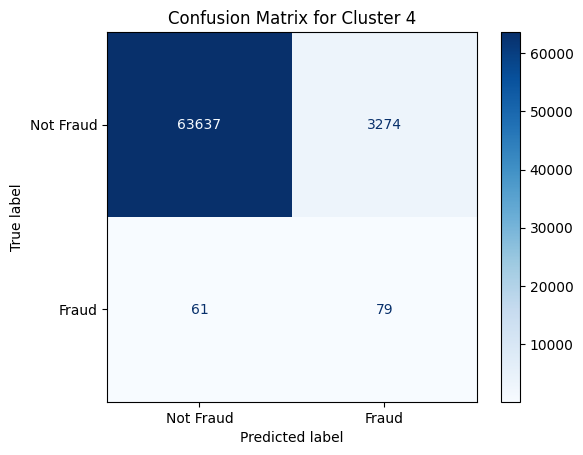


Cluster 4 Results:
Actual fraud counts:
140

Detected fraud counts:
79

Mean Anomaly Score by is_fraud:
0    2.103607
1    4.119720
dtype: float32

Top 10 Anomalies:
Index: 0, Anomaly Score: 30.04741668701172, Actual Fraud: 0
Index: 1, Anomaly Score: 27.874317169189453, Actual Fraud: 0
Index: 2, Anomaly Score: 22.43280792236328, Actual Fraud: 0
Index: 3, Anomaly Score: 19.579872131347656, Actual Fraud: 0
Index: 4, Anomaly Score: 18.815221786499023, Actual Fraud: 0
Index: 5, Anomaly Score: 15.007137298583984, Actual Fraud: 0
Index: 6, Anomaly Score: 14.31043529510498, Actual Fraud: 0
Index: 7, Anomaly Score: 13.938302993774414, Actual Fraud: 0
Index: 8, Anomaly Score: 12.78327465057373, Actual Fraud: 0
Index: 9, Anomaly Score: 12.294541358947754, Actual Fraud: 0


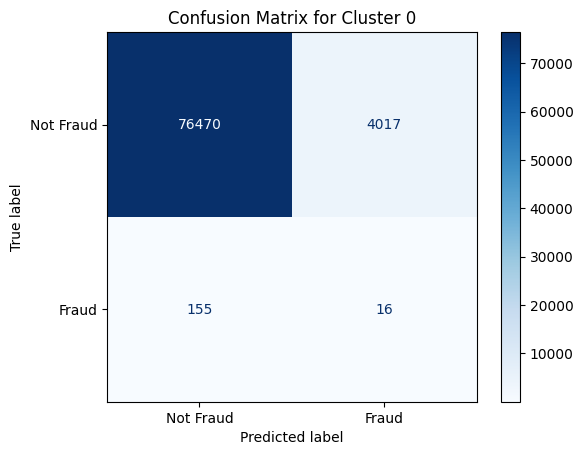


Cluster 0 Results:
Actual fraud counts:
171

Detected fraud counts:
16

Mean Anomaly Score by is_fraud:
0    2.746423
1    3.191925
dtype: float32

Top 10 Anomalies:
Index: 0, Anomaly Score: 25.8160457611084, Actual Fraud: 0
Index: 1, Anomaly Score: 19.82842445373535, Actual Fraud: 0
Index: 2, Anomaly Score: 12.093728065490723, Actual Fraud: 0
Index: 3, Anomaly Score: 11.718145370483398, Actual Fraud: 0
Index: 4, Anomaly Score: 11.406242370605469, Actual Fraud: 0
Index: 5, Anomaly Score: 11.317822456359863, Actual Fraud: 0
Index: 6, Anomaly Score: 10.970930099487305, Actual Fraud: 0
Index: 7, Anomaly Score: 10.11601734161377, Actual Fraud: 0
Index: 8, Anomaly Score: 8.213216781616211, Actual Fraud: 0
Index: 9, Anomaly Score: 7.979536533355713, Actual Fraud: 0


In [16]:
cluster_results = evaluate_autoencoder_on_test_per_cluster(
    autoencoder_models, 
    data_cluster_card_test, 
    feature_columns, 
    'cluster'
)